# Notebook Overview

**ACS tract rents: baseline and real change**

A public-facing visual demonstration of the cleaning pipeline: monthly median
**gross rent** from the 2012–2016 ACS beside its inflation-adjusted percentage
change to 2020–2024. The default scope is Alameda County, California. All
measurements use 2010 tract geography; this notebook follows
[04_assemble_tract_panel.Rmd](04_assemble_tract_panel.Rmd).

**Inputs** (paths relative to this repository):

- `../../../data/acs_full.feather` — canonical wide panel, one row per
  `tr2010_id`; see the [panel schema](schemas/acs_full.md).
- Census **2010** TIGER/Line tract boundaries. For Alameda:
  [tl_2010_06001_tract10.zip](https://www2.census.gov/geo/tiger/TIGER2010/TRACT/2010/tl_2010_06001_tract10.zip),
  reused or downloaded to `outputs/cache/tiger2010/tl_2010_06001_tract10.zip`.
- [tract_rent_maps.py](tract_rent_maps.py) — validation and plotting helpers.
  Python dependencies are declared in [requirements.txt](requirements.txt).

**Outputs** (default county; the suffix follows the selected county name):

- `outputs/figures/tract_rent_baseline_and_change_alameda.png` — paired static
  maps for the README/GitHub example.
- `outputs/figures/tract_rent_baseline_and_change_alameda.pdf` — equivalent
  vector figure.
- Inline figure, full-join counts, displayed status counts, omitted water-only
  count, unmatched GEOIDs, and plotted ranges.
  The original Census ZIP is cached; no intermediate dataset is saved.

**Steps**

1. Configure inputs and map scope.
2. Load and validate the ACS panel.
3. Load tract boundaries and join rent data.
4. Prepare map measures and plotting data.
5. Draw and save the paired maps.
6. Summarize validation.

Run from this repository or a subdirectory using a Python environment with the
declared dependencies. The first run downloads the configured county's public
boundary ZIP. No packages are installed by notebook cells. Real-panel execution
and review belong to the analyst; the offline check in
[tests/test_tract_rent_maps.py](tests/test_tract_rent_maps.py) uses synthetic data.

# 1. Configure inputs and map scope

Paths are anchored to the repository's `.here` marker (the Python equivalent of
this project's R `here::here()` usage), without changing the working directory.
Select one county using its three-character FIPS code from the panel's 14-county
universe. Both panels use California Albers, EPSG:3310, and identical extents.
Existing figure files require an explicit `overwrite_figures = True` setting.

In [21]:
from pathlib import Path
import sys

import geopandas as gpd
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

repo_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / '.here').is_file() and (path / '05_map_tract_rents.ipynb').is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError('Launch the notebook from the acs_tract repository or a subdirectory.')
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from tract_rent_maps import (
    COUNTIES, PANEL_COLUMNS, DISPLAY_STATUSES,
    county_scope, validate_panel, cache_boundaries, load_boundaries,
    join_panel_to_boundaries, prepare_map_measures, display_summary,
    draw_paired_maps, save_paired_figure,
)

print(f'Python {sys.version.split()[0]} | GeoPandas {gpd.__version__} | '
      f'Matplotlib {matplotlib.__version__} | pandas {pd.__version__}')

Python 3.9.6 | GeoPandas 1.0.1 | Matplotlib 3.9.4 | pandas 2.3.3


In [22]:
county_fips = '001'  # Alameda; see COUNTIES for other supported California counties.
overwrite_figures = True
map_crs = 'EPSG:3310'
panel_path = (repo_root / '../../../data/acs_full.feather').resolve()
boundary_cache_dir = repo_root / 'outputs/cache/tiger2010'
figure_dir = repo_root / 'outputs/figures'

county_name, geographic_suffix = county_scope(county_fips)
output_stem = figure_dir / f'tract_rent_baseline_and_change_{geographic_suffix}'
print(f'Scope: {county_name} County, California (06{county_fips})')
print(f'Canonical input: {panel_path}')
print(f'Figure outputs: {output_stem}.png and {output_stem}.pdf')
print('Available county FIPS:', COUNTIES)

Scope: Alameda County, California (06001)
Canonical input: /Volumes/Research/1active/ADU_Rent/data/acs_full.feather
Figure outputs: /Volumes/Research/1active/ADU_Rent/scripts/cleaning/acs_tract/outputs/figures/tract_rent_baseline_and_change_alameda.png and /Volumes/Research/1active/ADU_Rent/scripts/cleaning/acs_tract/outputs/figures/tract_rent_baseline_and_change_alameda.pdf
Available county FIPS: {'001': 'Alameda', '013': 'Contra Costa', '037': 'Los Angeles', '041': 'Marin', '055': 'Napa', '059': 'Orange', '065': 'Riverside', '071': 'San Bernardino', '075': 'San Francisco', '081': 'San Mateo', '085': 'Santa Clara', '095': 'Solano', '097': 'Sonoma', '111': 'Ventura'}


# 2. Load and validate the ACS panel

### Decision: Use canonical gross rents in their existing 2024 dollars

`rentE_16` is baseline monthly median **gross** rent (B25064), already multiplied
by exactly **1.307** in notebook 4. `interp_rent` is selected 2024 gross rent:
native tract median on geographically consistent links, or a median interpolated
from block-group rent distributions allocated to 2010 tracts elsewhere. Both
are in 2024 dollars. No additional inflation adjustment is applied here.
`interp_rentPOST` is the canonical later/baseline ratio, not a percent.

The canonical file is **wide**, with both periods on each unique 2010 tract row;
no reshape is needed. Check keys before county selection, then report retained
rows. Reject numeric/damaged GEOIDs, duplicates, missing current fields, and
inconsistent rent/status/flag/bound bundles instead of inferring replacements.
The source bounds ($4,574.50 baseline; $3,500 later) check the existing schema;
flags determine top-coding, so an observed $3,500 later rent remains usable.

In [23]:
if not panel_path.is_file():
    raise FileNotFoundError(f'Canonical panel not found: {panel_path}. Run notebook 4 separately.')
panel = pd.read_feather(panel_path, columns=PANEL_COLUMNS)
validate_panel(panel)
panel['tr2010_id'] = panel['tr2010_id'].astype('string')
panel_count = len(panel)
county_panel = panel.loc[panel['tr2010_id'].str.startswith(f'06{county_fips}')].copy()
print(f'Panel loaded: {panel_count:,} unique tracts; county selection: {len(county_panel):,} retained.')
print('Expected: county subset only, one row per tract, no sample or quality filtering.')
if county_panel.empty:
    print('REVIEW: no canonical panel rows for this county; every boundary will be unavailable.')
display(county_panel[['rentE_16', 'interp_rent', 'interp_rentPOST']].agg(['count', 'min', 'max']))
display(county_panel.groupby(['acs_source_24', 'rent_status_16', 'rent_status_24'], dropna=False)
        .size().rename('tracts').reset_index())

Panel loaded: 5,514 unique tracts; county selection: 361 retained.
Expected: county subset only, one row per tract, no sample or quality filtering.


,rentE_16,interp_rent,interp_rentPOST
count,357.000,317.000000,316.000000
min,782.893,811.423077,0.207564
max,4574.500,3448.115132,2.580279


,acs_source_24,rent_status_16,rent_status_24,tracts
0,bg_agg,observed,observed,160
1,bg_agg,observed,top_coded,34
2,bg_agg,unavailable_other,observed,1
3,bg_agg,unavailable_other,top_coded,1
4,bg_agg,unavailable_other,unavailable_other,1
5,tract,observed,observed,156
6,tract,observed,top_coded,7
7,tract,unavailable_other,unavailable_other,1


# 3. Load tract boundaries and join rent data

### Decision: Use 2010 Census polygons and retain the full county boundary frame

The county ZIP comes from the Census Bureau's
[2010 TIGER/Line archive](https://www2.census.gov/geo/tiger/TIGER2010/TRACT/2010/).
The [2010 technical record layout, Appendix A, page A-121](https://www2.census.gov/geo/pdfs/maps-data/data/tiger/tgrshp2010/TGRSHP10SF1AA.pdf)
defines `GEOID10`, `STATEFP10`, and `COUNTYFP10`. The download is cached as the
original ZIP; its source URL and SHA-256 are printed each run. Invalid cache
files stop execution; they are never silently replaced. Current/2020 tract
boundaries are not compatible with these harmonized values. The cached
metadata defines `ALAND10` and `AWATER10` as land and water area in square
meters. Retain both attributes; absent fields or values remain unknown.

The left join retains every county polygon, including water/special tracts,
and must be one-to-one. Boundary-only records receive an unavailable display
status. Panel-only records cannot be mapped; report their exact IDs for analyst
review without guessing a replacement geography. Unmatched IDs in either
direction need an explanation before publishing.

In [24]:
boundary_path = cache_boundaries(boundary_cache_dir, county_fips)
boundaries = load_boundaries(boundary_path, county_fips, map_crs)
print(f'2010 county boundary rows: {len(boundaries):,}; retained after projection: {len(boundaries):,}.')
mapped, coverage = join_panel_to_boundaries(boundaries, county_panel)
print(f'Left join: {len(boundaries):,} polygons -> {len(mapped):,} rows; expected no multiplication or loss.')
coverage_counts = coverage['coverage'].value_counts().reindex(
    ['matched', 'boundary_only', 'panel_only'], fill_value=0,
)
display(coverage_counts.rename('tracts').to_frame())
for direction in ['boundary_only', 'panel_only']:
    unmatched = coverage.loc[coverage['coverage'].eq(direction), ['tr2010_id']]
    print(f'{direction}: {len(unmatched):,}')
    print(unmatched.to_string(index=False) if len(unmatched) else '(none)')
if coverage_counts[['boundary_only', 'panel_only']].sum():
    print('REVIEW: explain all unmatched IDs before publishing; panel-only rows are absent from the maps.')

Boundary source: https://www2.census.gov/geo/tiger/TIGER2010/TRACT/2010/tl_2010_06001_tract10.zip
Cache: /Volumes/Research/1active/ADU_Rent/scripts/cleaning/acs_tract/outputs/cache/tiger2010/tl_2010_06001_tract10.zip
SHA-256: fedef46af216a3607e871fdcd05cbd4a438bd15b2a953f24e3146059bb2711b9
2010 county boundary rows: 361; retained after projection: 361.
Left join: 361 polygons -> 361 rows; expected no multiplication or loss.


,tracts
coverage,
matched,361
boundary_only,0
panel_only,0


boundary_only: 0
(none)
panel_only: 0
(none)


# 4. Prepare map measures and plotting data

### Decision: Separate top-coded rents from other unavailable rents

For the baseline, color finite observed rent levels (including a valid zero).
For change, require **finite, strictly positive rents in both periods** and
calculate `100 * (interp_rent / rentE_16 - 1)`. Observed zeros remain visible
in the baseline but cannot supply a change value. This is a raw level/percentage
comparison; no demeaning, quantiles, CV threshold, parcel/ADU fields, or downstream
sample restrictions enter the map.

| Display status | Baseline map | Change map |
|---|---|---|
| Value | Observed baseline rent | Observed positive baseline and later rents |
| Top-coded (hatched) | Confirmed baseline top-code | Confirmed top-code in either period |
| Missing / unavailable (gray) | Other missing/unavailable baseline or no panel row | Other unavailable/zero rent in either period or no panel row |

Confirmed top-coding takes precedence when the other period is also unavailable;
this preserves the known censoring information. Under the panel contract,
`unavailable_other` and `unresolved` both have missing numeric rent and no
confirmed top-code flag.

### Decision: Omit confirmed water-only tracts only from the plotting frame

Keep the full joined `mapped` frame intact. Build `plot_data` by omitting only
tracts with **`ALAND10 == 0` and `AWATER10 > 0`**, with both areas known. Missing
area attributes do not qualify for omission. Preserve every tract containing
land, including mixed land/water, unavailable, and top-coded tracts; retain
their existing values and status rules. This removes water-only polygons from
the display without changing the analysis data or clipping tract geometries.

Both panels use `plot_data` for every fill and outline layer, their shared
extent, status counts, and plotted ranges. Report the number of omitted
water-only tracts separately from the displayed counts.

In [25]:
mapped = prepare_map_measures(mapped)
known_area = mapped[['ALAND10', 'AWATER10']].notna().all(axis=1)
confirmed_water_only = (
    known_area & mapped['ALAND10'].eq(0) & mapped['AWATER10'].gt(0)
).fillna(False)
plot_data = mapped.loc[~confirmed_water_only].copy()
omitted_water_only_count = int(confirmed_water_only.sum())
status_counts, plotted_ranges = display_summary(plot_data)
print(f'After preparing display measures: {len(mapped):,} full joined polygons; expected unchanged.')
print(f'Plotting frame: {len(mapped):,} -> {len(plot_data):,} tracts; '
      f'omitted confirmed water-only tracts: {omitted_water_only_count:,}.')
print(f'Tracts with unknown land/water area retained: {int((~known_area).sum()):,}.')
print('Status counts and ranges below describe displayed tracts only.')
display(status_counts)
display(plotted_ranges.rename(index={
    'baseline_rent': 'Baseline monthly gross rent (2024 dollars)',
    'rent_change_pct': 'Inflation-adjusted rent change (%)',
}))
valid_change = mapped['change_status'].eq('value')
assert np.allclose(mapped.loc[valid_change, 'rent_change_pct'],
                   100 * (mapped.loc[valid_change, 'interp_rentPOST'] - 1),
                   rtol=1e-10, atol=1e-10)


After preparing display measures: 361 full joined polygons; expected unchanged.
Plotting frame: 361 -> 360 tracts; omitted confirmed water-only tracts: 1.
Tracts with unknown land/water area retained: 0.
Status counts and ranges below describe displayed tracts only.


,baseline,change
display_status,,
value,357,316
top_coded,0,42
unavailable,3,2


,count,min,max
Baseline monthly gross rent (2024 dollars),357.0,782.893000,4574.500000
Inflation-adjusted rent change (%),316.0,-79.243633,158.027905


# 5. Draw and save the paired maps

The sequential baseline scale spans its full observed range. The diverging
change scale is symmetric around zero and spans the largest absolute change;
there is no trimming or winsorization. Single-valued baseline scales are padded
only to make a colorbar possible; an all-zero change map uses a ±1% legend.
If no values qualify, the panel explicitly says so and retains its status fills.
Both maps use only `plot_data` for identical extents, projected geometry,
status fills, and thin tract outlines. Any county outline derived from tract
geometries must also use this plotting frame. There is no online basemap.
The PDF retains vector tract geometry.

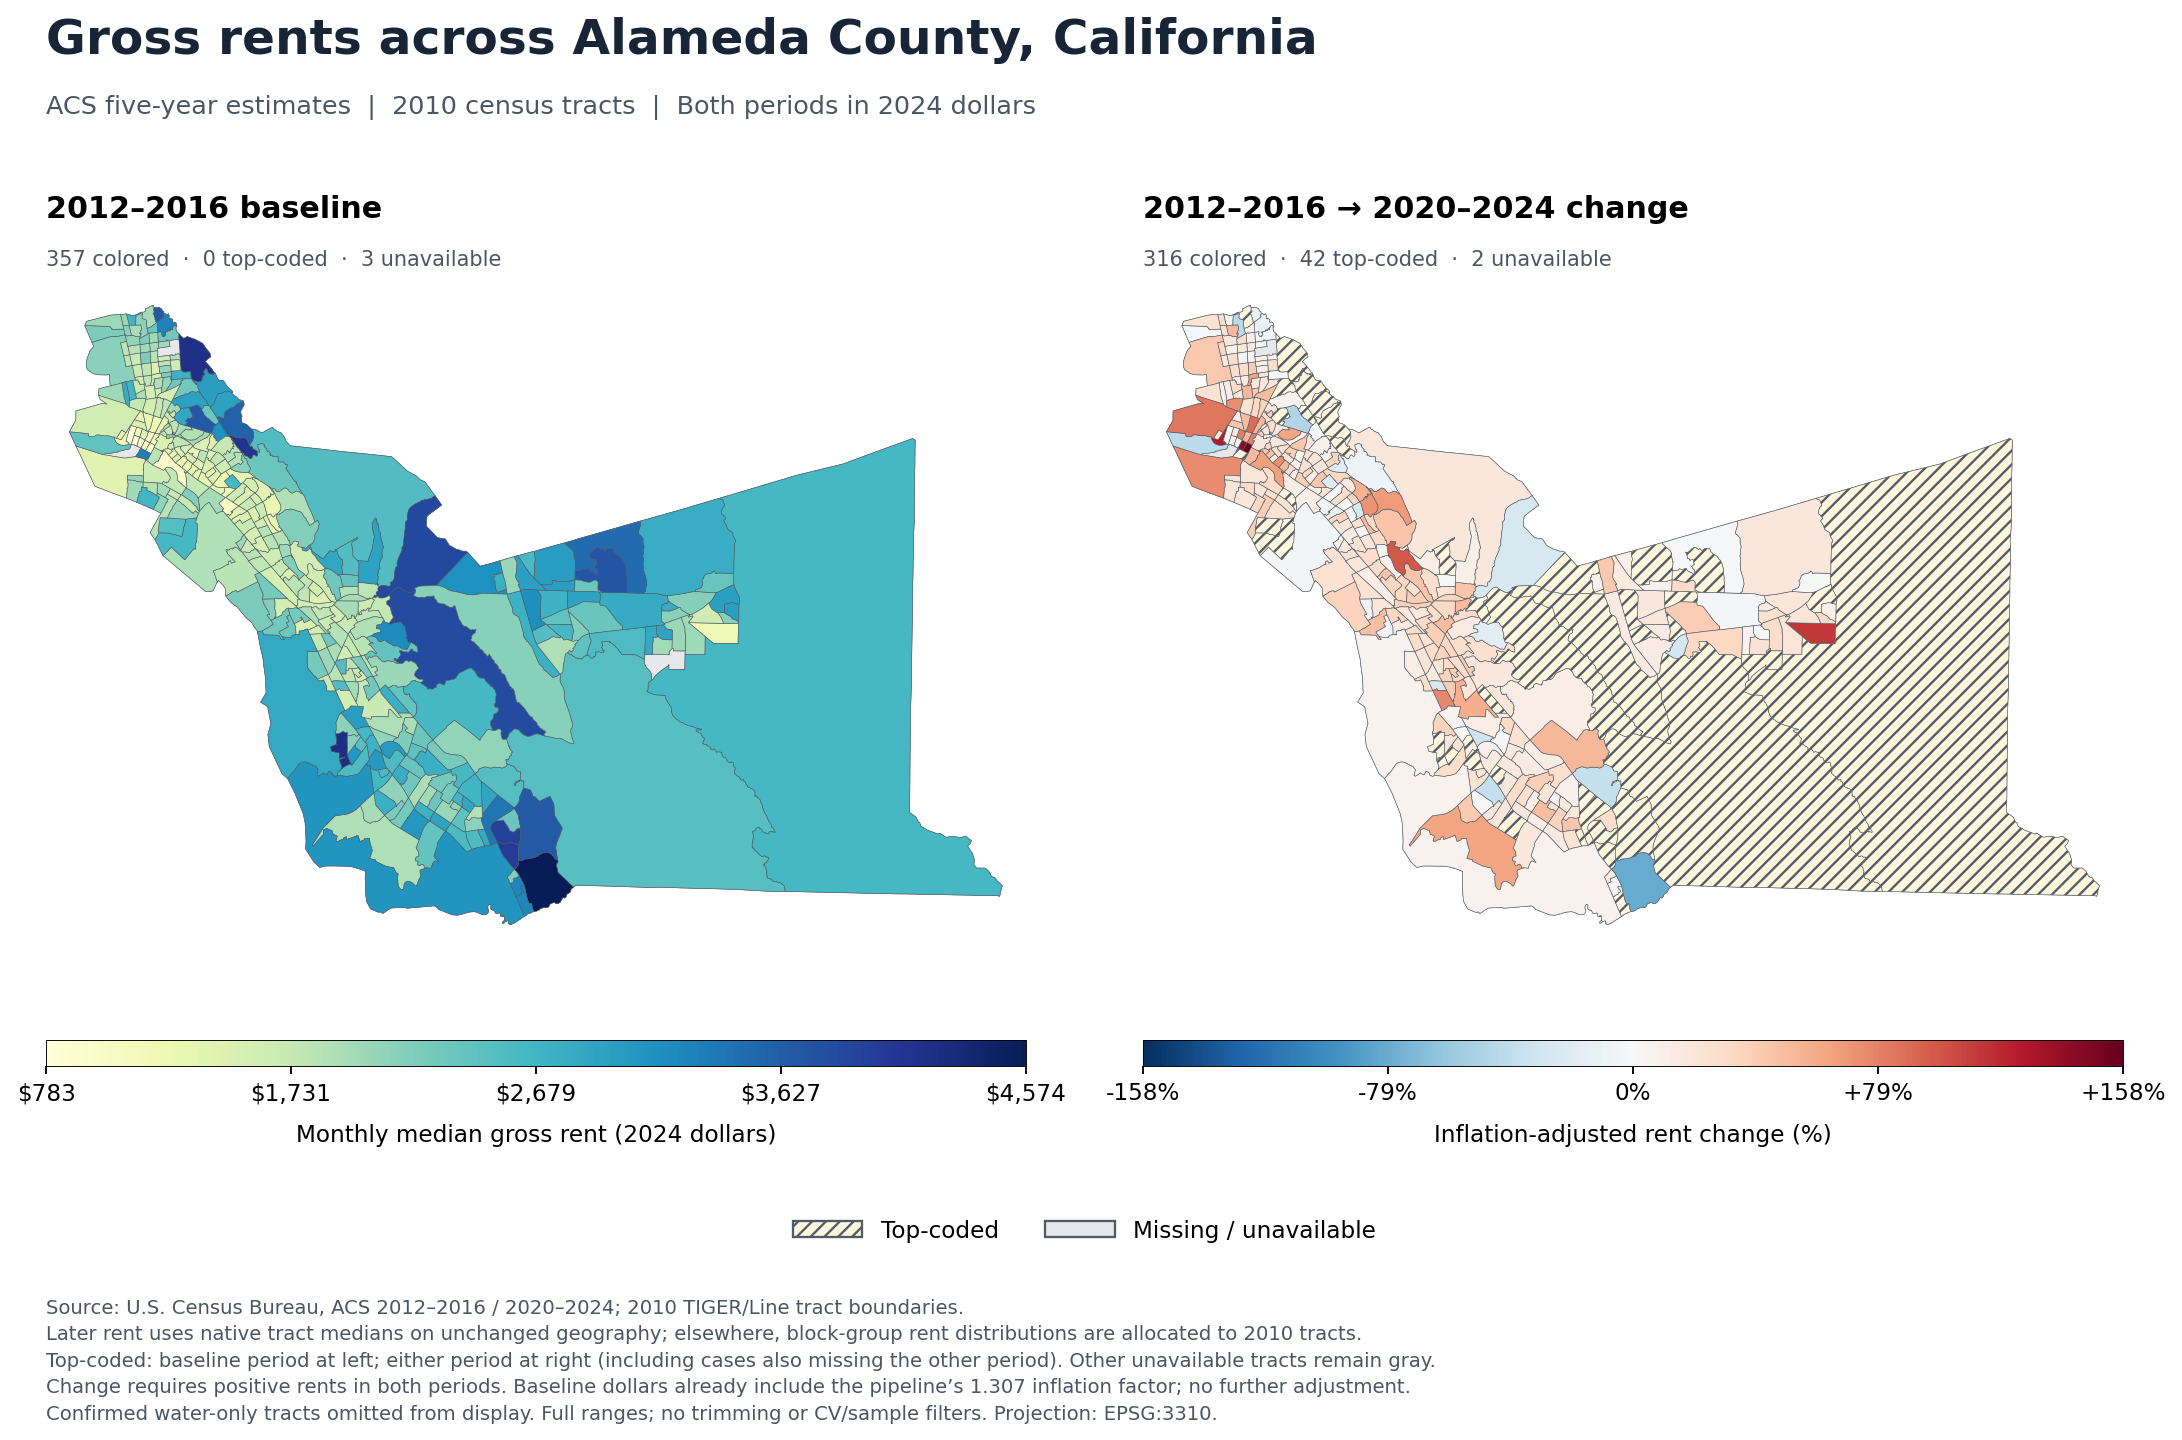

Replacing /Volumes/Research/1active/ADU_Rent/scripts/cleaning/acs_tract/outputs/figures/tract_rent_baseline_and_change_alameda.png
Replacing /Volumes/Research/1active/ADU_Rent/scripts/cleaning/acs_tract/outputs/figures/tract_rent_baseline_and_change_alameda.pdf


In [26]:
fig, map_axes = draw_paired_maps(plot_data, f'{county_name} County, California')
assert map_axes[0].get_xlim() == map_axes[1].get_xlim()
assert map_axes[0].get_ylim() == map_axes[1].get_ylim()
display(fig)
export_paths = save_paired_figure(fig, output_stem, overwrite=overwrite_figures)
plt.close(fig)

# 6. Summarize validation

The checks below reconcile the selected panel and boundary frames separately,
including unmatched records, then verify that every joined polygon has one
display status per panel. Reconcile displayed and omitted counts against the
full join, and verify that plotting preserves retained rows exactly. Status
counts and ranges refer only to displayed tracts. A clean run confirms
construction and export; it does not replace an analyst's review of the
geographic joins and figure.

In [27]:
assert boundaries['tr2010_id'].is_unique and mapped['tr2010_id'].is_unique
assert len(mapped) == len(boundaries)
assert set(mapped['tr2010_id']) == set(boundaries['tr2010_id'])
assert coverage_counts['matched'] + coverage_counts['boundary_only'] == len(boundaries)
assert coverage_counts['matched'] + coverage_counts['panel_only'] == len(county_panel)
assert plot_data['tr2010_id'].is_unique
assert len(plot_data) + omitted_water_only_count == len(mapped)
assert plot_data.equals(mapped.loc[~confirmed_water_only])
assert not confirmed_water_only.loc[~known_area].any()
assert set(mapped.loc[mapped['ALAND10'].gt(0), 'tr2010_id']).issubset(plot_data['tr2010_id'])
assert status_counts.sum().eq(len(plot_data)).all()
full_status_counts, _ = display_summary(mapped)
omitted_status_counts, _ = display_summary(mapped.loc[confirmed_water_only])
assert (full_status_counts - status_counts).equals(omitted_status_counts)
for period, value_column in [('baseline', 'baseline_rent'), ('change', 'rent_change_pct')]:
    status = mapped[f'{period}_status']
    assert status.isin(DISPLAY_STATUSES).all() and status.notna().all()
    assert status.eq('value').equals(mapped[value_column].notna())
    assert np.isfinite(mapped.loc[status.eq('value'), value_column]).all()
assert not mapped.loc[mapped['tc_flag_rent_16'].eq(1), 'baseline_status'].eq('value').any()
either_top = mapped['tc_flag_rent_16'].eq(1) | mapped['tc_flag_rent_24'].eq(1)
assert not mapped.loc[either_top, 'change_status'].eq('value').any()
assert mapped.loc[valid_change, ['rentE_16', 'interp_rent']].gt(0).all().all()
assert mapped.loc[mapped['panel_join'].eq('left_only'), ['baseline_status', 'change_status']].eq('unavailable').all().all()

print(f'Panel: {panel_count:,} rows across the target counties; {len(county_panel):,} selected county rows.')
print(f'County boundaries: {len(boundaries):,}; full joined polygons: {len(mapped):,}.')
print(f'Displayed tracts: {len(plot_data):,}; omitted confirmed water-only tracts: {omitted_water_only_count:,}.')
display(coverage_counts.rename('tracts').to_frame())
display(status_counts)
display(plotted_ranges)
display(pd.DataFrame({'export': [str(path.relative_to(repo_root)) if path.is_relative_to(repo_root)
                                else str(path) for path in export_paths],
                      'bytes': [path.stat().st_size for path in export_paths]}))
assert all(path.is_file() and path.stat().st_size > 0 for path in export_paths)
print('Passed: tract uniqueness, one-to-one joins, display-only water exclusion, status/count reconciliation, measure rules, and PNG/PDF export.')

Panel: 5,514 rows across the target counties; 361 selected county rows.
County boundaries: 361; full joined polygons: 361.
Displayed tracts: 360; omitted confirmed water-only tracts: 1.


,tracts
coverage,
matched,361
boundary_only,0
panel_only,0


,baseline,change
display_status,,
value,357,316
top_coded,0,42
unavailable,3,2


,count,min,max
baseline_rent,357.0,782.893000,4574.500000
rent_change_pct,316.0,-79.243633,158.027905


,export,bytes
0,outputs/figures/tract_rent_baseline_and_change...,708046
1,outputs/figures/tract_rent_baseline_and_change...,3188043


Passed: tract uniqueness, one-to-one joins, display-only water exclusion, status/count reconciliation, measure rules, and PNG/PDF export.


**Analyst acceptance checks before publishing**

- Confirm that the printed archive URL, `GEOID10` fields, and cache provenance
  refer to 2010 tracts, and that both maps share the same extent/projection.
- Explain every boundary-only and panel-only GEOID; preserve the full join
  and report any panel records without boundaries. Omit only confirmed water-only
  tracts from all plotting layers; retain unavailable tracts containing land
  and tracts with unknown area attributes.
- Confirm the canonical input was produced by current notebook 4: both rent
  periods already use 2024 dollars, baseline conversion is exactly 1.307, and
  displayed percentages agree with `100 * (interp_rentPOST - 1)` where eligible.
- Review full-join, displayed, and omitted counts plus plotted value ranges.
  For the current Alameda inputs, expect 361 joined and 360 displayed tracts,
  with one water-only tract omitted. Baseline counts are 357 colored, 0 top-coded,
  and 3 unavailable; change counts are 316 colored, 42 top-coded, and 2 unavailable.
  Top-coded polygons must be hatched, distinct from gray unavailable polygons.
- Inspect titles, units, ACS windows, source/harmonization notes, outlines, and
  colorbar/legend readability in both the inline figure and exported PNG/PDF.
- Confirm both exports exist. The README's Alameda example points to the default
  PNG and becomes available after this real-panel run; use no synthetic figure
  in its place.

The schema specifies all rent/quality fields and the Census source specifies the
boundary vintage. No unresolved schema or source choice is assumed here.